<a href="https://colab.research.google.com/github/ahmadmukhtasor-0309-lgtm/Tugas-Machine-Learning/blob/main/Neural_Network_MLP_Keras.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# Praktikum 12 - Neural Network (MLP dengan Keras)

## Perhitungan (forward pass satu neuron, ReLU)

In [1]:
import numpy as np

x = np.array([0.5, -0.2, 0.8])
w = np.array([0.4, 0.6, -0.3])
b = 0.1

z = np.dot(x, w) + b
a = max(0, z)
print("z =", round(z, 2))
print("a = ReLU(z) =", a)

z = -0.06
a = ReLU(z) = 0


## Persiapan Library

In [2]:
import numpy as np
import matplotlib.pyplot as plt
import tensorflow as tf
from tensorflow import keras
from sklearn.datasets import load_digits
from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler

## Import Dataset

In [3]:
digits = load_digits()
X, y = digits.data, digits.target
X_train, X_test, y_train, y_test = train_test_split(X, y,
    test_size=0.2, random_state=42, stratify=y)

## Preprocessing

In [4]:
scaler = StandardScaler()
X_train = scaler.fit_transform(X_train)
X_test = scaler.transform(X_test)

## Training Model (Keras Sequential API)
Seed ditambahkan agar hasil dapat direproduksi.

In [5]:
keras.utils.set_random_seed(42)

model = keras.Sequential([ keras.layers.Dense(64,
    activation="relu", input_shape=(X_train.shape[1],)),
    keras.layers.Dropout(0.3), keras.layers.Dense(32,
    activation="relu"), keras.layers.Dense(10,
    activation="softmax")
])

model.compile(optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

history = model.fit(X_train, y_train, validation_split=0.2,
    epochs=50, batch_size=32, verbose=0)

/usr/local/lib/python3.13/dist-packages/keras/src/layers/core/dense.py:106: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(activity_regularizer=activity_regularizer, **kwargs)


## Evaluasi

In [6]:
test_loss, test_acc = model.evaluate(X_test, y_test,
    verbose=0)
print(f"Akurasi Test: {test_acc:.3f}")

Akurasi Test: 0.983


## Visualisasi

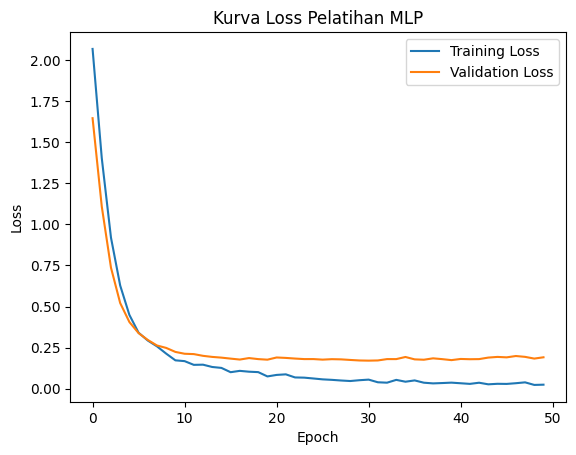

In [7]:
plt.plot(history.history["loss"],
    label="Training Loss")
plt.plot(history.history["val_loss"],
    label="Validation Loss")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Kurva Loss Pelatihan MLP")
plt.legend()
plt.show()

### Interpretasi
Jika kurva validation loss mulai naik sementara training loss terus turun, hentikan pelatihan lebih awal (*early stopping*) atau tambahkan regularisasi seperti dropout (sudah diterapkan pada contoh di atas). Bandingkan pula akurasi akhir dengan model Random Forest pada Bab 10 menggunakan dataset yang sama, untuk melihat apakah kompleksitas tambahan MLP memberikan peningkatan performa yang sepadan dengan biaya komputasinya.

In [8]:
train_loss = np.array(history.history["loss"])
val_loss = np.array(history.history["val_loss"])
best_ep = int(np.argmin(val_loss)) + 1
print(f"Epoch dengan validation loss terendah : {best_ep} dari {len(val_loss)}")
print(f"Validation loss terendah / akhir      : {val_loss.min():.4f} / {val_loss[-1]:.4f}")
print(f"Training loss akhir                   : {train_loss[-1]:.4f}")
if val_loss[-1] > val_loss.min() * 1.05:
    print("-> Validation loss naik setelah epoch terbaik: indikasi overfitting.")
else:
    print("-> Validation loss tidak naik signifikan: tidak ada overfitting yang berarti.")

Epoch dengan validation loss terendah : 31 dari 50
Validation loss terendah / akhir      : 0.1708 / 0.1913
Training loss akhir                   : 0.0245
-> Validation loss naik setelah epoch terbaik: indikasi overfitting.


**Perbandingan dengan Random Forest** (sesuai dengan interpretasi; data sama dan split sama):

In [9]:
import time
from sklearn.ensemble import RandomForestClassifier
from sklearn.metrics import accuracy_score

t0 = time.time()
rf = RandomForestClassifier(n_estimators=100, random_state=42).fit(X_train, y_train)
rf_acc = accuracy_score(y_test, rf.predict(X_test))
rf_time = time.time() - t0

print(f"Random Forest : akurasi test = {rf_acc:.3f}, waktu latih = {rf_time:.1f} detik")
print(f"MLP (Keras)   : akurasi test = {test_acc:.3f}")

Random Forest : akurasi test = 0.964, waktu latih = 0.5 detik
MLP (Keras)   : akurasi test = 0.983



## Eksperimen Arsitektur MLP




In [10]:
hasil_arsitektur = []

arsitektur_list = [ [32], [64, 32], [128, 64, 32] ]
for arsitektur in arsitektur_list:
    keras.utils.set_random_seed(42)
    layers = [keras.layers.Dense(n,
        activation="relu") for n in arsitektur]
    model = keras.Sequential([keras.layers.Input(shape=(X_train.shape[1],))] + layers + [keras.layers.Dense(10,
        activation="softmax")])
    model.compile(optimizer="adam",
        loss="sparse_categorical_crossentropy",
        metrics=["accuracy"])
    history = model.fit(X_train, y_train,
        validation_split=0.2, epochs=30, verbose=0)
    val_acc_akhir = history.history['val_accuracy'][-1]
    print(f"Arsitektur {arsitektur}: val_accuracy akhir = {val_acc_akhir:.3f}")


    _, t_acc = model.evaluate(X_test, y_test, verbose=0)
    hasil_arsitektur.append({
        "Arsitektur": str(arsitektur),
        "Hidden layer": len(arsitektur),
        "Parameter": model.count_params(),
        "Val accuracy": round(val_acc_akhir, 3),
        "Test accuracy": round(t_acc, 3)})

Arsitektur [32]: val_accuracy akhir = 0.951
Arsitektur [64, 32]: val_accuracy akhir = 0.958
Arsitektur [128, 64, 32]: val_accuracy akhir = 0.965


**Ringkasan perbandingan arsitektur** :

In [11]:
import pandas as pd

tabel = pd.DataFrame(hasil_arsitektur)
display(tabel)

terbaik = tabel.loc[tabel["Val accuracy"].idxmax()]
print(f"Val accuracy tertinggi : arsitektur {terbaik['Arsitektur']} ({terbaik['Val accuracy']:.3f})")
selisih = tabel["Val accuracy"].max() - tabel["Val accuracy"].min()
print(f"Selisih val accuracy terbesar antar arsitektur: {selisih:.3f}")
if selisih < 0.02:
    print("-> Perbedaan kecil: menambah layer/neuron pada dataset digits tidak memberi peningkatan berarti.")
else:
    print("-> Perbedaan cukup terlihat: arsitektur memengaruhi performa pada dataset ini.")

,Arsitektur,Hidden layer,Parameter,Val accuracy,Test accuracy
0,[32],1,2410,0.951,0.975
1,"[64, 32]",2,6570,0.958,0.969
2,"[128, 64, 32]",3,18986,0.965,0.983


Val accuracy tertinggi : arsitektur [128, 64, 32] (0.965)
Selisih val accuracy terbesar antar arsitektur: 0.014
-> Perbedaan kecil: menambah layer/neuron pada dataset digits tidak memberi peningkatan berarti.


### Analisanya
- **Jumlah parameter** meningkat tajam seiring bertambahnya layer dan neuron (`[32]` < `[64, 32]` < `[128, 64, 32]`), sehingga waktu latih dan risiko overfitting ikut meningkat.
- Bandingkan **val accuracy** dan **test accuracy**: jika arsitektur yang lebih besar tidak memberi kenaikan yang berarti, arsitektur yang lebih sederhana lebih efisien. Dataset `digits` berukuran kecil (1797 sampel) dan relatif mudah, sehingga umumnya satu atau dua hidden layer sudah cukup, dan model yang jauh lebih besar tidak banyak menambah akurasi.
- Pilih arsitektur dengan akurasi validasi tertinggi, atau yang paling sederhana jika selisihnya kecil (prinsip *Occam*). Kesimpulan akhir mengikuti hasil keluaran sel ringkasan di atas.

##Early Stopping


In [12]:
keras.utils.set_random_seed(42)
model = keras.Sequential([
    keras.layers.Input(shape=(X_train.shape[1],)),
    keras.layers.Dense(64, activation="relu"),
    keras.layers.Dropout(0.3),
    keras.layers.Dense(32, activation="relu"),
    keras.layers.Dense(10, activation="softmax")])
model.compile(optimizer="adam",
    loss="sparse_categorical_crossentropy",
    metrics=["accuracy"])

early_stop = keras.callbacks.EarlyStopping(monitor="val_loss",
    patience=5, restore_best_weights=True)
history = model.fit(X_train, y_train, validation_split=0.2,
    epochs=100, callbacks=[early_stop], verbose=0)
print("Pelatihan berhenti pada epoch:",
    len(history.history["loss"]))

Pelatihan berhenti pada epoch: 25


**Evaluasi dan kurva loss dengan early stopping**:

Berhenti pada epoch 25 dari maksimum 100
Epoch terbaik (val_loss terendah): 20  -> bobot epoch ini dipulihkan (restore_best_weights=True)
Akurasi test dengan early stopping: 0.975


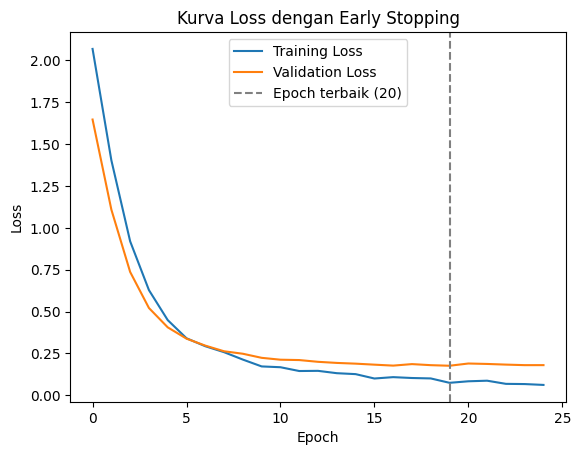

In [13]:
val_loss = np.array(history.history["val_loss"])
best_ep = int(np.argmin(val_loss)) + 1
n_ep = len(val_loss)
_, acc_es = model.evaluate(X_test, y_test, verbose=0)

print(f"Berhenti pada epoch {n_ep} dari maksimum 100")
print(f"Epoch terbaik (val_loss terendah): {best_ep}  -> bobot epoch ini dipulihkan (restore_best_weights=True)")
print(f"Akurasi test dengan early stopping: {acc_es:.3f}")

plt.plot(history.history["loss"], label="Training Loss")
plt.plot(history.history["val_loss"], label="Validation Loss")
plt.axvline(best_ep - 1, ls="--", c="gray", label=f"Epoch terbaik ({best_ep})")
plt.xlabel("Epoch"); plt.ylabel("Loss")
plt.title("Kurva Loss dengan Early Stopping")
plt.legend()
plt.show()

### Analisanya
- `EarlyStopping(monitor="val_loss", patience=5)` menghentikan pelatihan jika validation loss tidak membaik selama 5 epoch berturut-turut. Karena itu pelatihan berhenti jauh sebelum batas 100 epoch (jumlah epoch sebenarnya dicetak oleh sel di atas).
- `restore_best_weights=True` mengembalikan bobot ke epoch dengan validation loss terendah, bukan bobot epoch terakhir (yang sudah 5 epoch melewati titik terbaik). Itu sebabnya epoch berhenti = epoch terbaik + 5.
- Manfaat: mencegah overfitting (training loss terus turun sementara validation loss mulai naik), menghemat waktu komputasi, dan tidak perlu menebak jumlah epoch secara manual.
- Early stopping dapat dikombinasikan dengan dropout (sudah dipakai pada model ini) untuk regularisasi yang lebih kuat.